# Credit portfolio data pipeline

**What this does:** generates a synthetic credit bureau dataset with [creforge](https://github.com/chowkuanlaw/creforge) (20,000 borrowers, 36 months of payment history), corrupts a copy with 16 kinds of realistic data fault, then runs it through a pipeline:

1. **Load** the raw CSVs, everything as text
2. **Validate** with data-quality checks, producing a findings list
3. **Clean** what can be rescued, remove what can't, log every step
4. **Summarise**: portfolio by product, write-off rates, risk by grade, arrears trend, roll rates, vintage curves
5. **Report** to Excel and charts

Because creforge keeps an answer key of every fault it injected, the checks can be **scored**: what share of real faults they caught, and how many false alarms they raised.

Run the cells top to bottom (Runtime, Run all). Takes about two minutes.

## 0. Install creforge

In [1]:
!pip install -q creforge openpyxl

## 1. The pipeline code

This cell writes the pipeline to a file, `pipeline.py`, so it can be imported like any other module. Read it top to bottom: each stage is a section, each check is a few lines with a comment saying what it catches.

In [2]:
%%writefile pipeline.py
"""
pipeline.py: a data pipeline for loan-level credit data.

Takes a creforge dataset (synthetic credit bureau data: accounts plus their monthly
payment history), and runs it through five stages:

    1. LOAD       read the raw CSV files, everything as text
    2. VALIDATE   run data-quality checks and list every problem found
    3. CLEAN      fix what can be fixed, remove what can't, log every change
    4. SUMMARISE  portfolio tables: balances, arrears, write-offs, risk by grade,
                  roll rates, vintage curves
    5. REPORT     save the tables to Excel and the charts as PNG files

Run it with one line:

    from pipeline import run
    results = run("dirty", "output")
"""

import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Reference lists: the only values each code column is allowed to take
# ---------------------------------------------------------------------------
DPD_ORDER = ["0", "1-29", "30-59", "60-89", "90-119", "120+"]   # worst is last
STATUSES = ["current", "delinquent", "restructured", "written_off", "closed"]
PRODUCTS = ["credit_card", "personal_loan", "mortgage", "auto_loan", "overdraft", "bnpl"]
CLOSE_REASONS = ["paid_off", "written_off", "closed_by_customer", "refinanced"]

# Columns that must never be blank
REQUIRED = {
    "account": ["account_id", "subject_id", "lender_id", "product_type", "open_date", "interest_rate"],
    "account_month": ["account_id", "as_of_month", "balance", "amount_due", "amount_paid",
                      "dpd_bucket", "months_in_arrears", "status"],
}

# A value more than this many times its normal level is treated as a scale error
# (e.g. a balance keyed in pence instead of pounds, which is 100x too big)
SCALE_LIMIT = 20


# ===========================================================================
# 1. LOAD
# ===========================================================================
def load_table(folder, table):
    """Read every part file of one table into a single DataFrame.

    Everything is read as text (dtype=str). If we let pandas guess the types, a single
    "N/A" in a number column would quietly turn the whole column into text, and a date
    written as 31/01/2024 would be misread. Reading as text first means *we* decide
    what counts as a valid number or date, and we can report the rows that fail.
    """
    files = sorted(glob.glob(os.path.join(folder, table, "*.csv")))
    if not files:
        raise FileNotFoundError(f"No CSV files found in {os.path.join(folder, table)}")
    parts = [pd.read_csv(f, dtype=str, keep_default_na=False, na_values=[""]) for f in files]
    return pd.concat(parts, ignore_index=True)


def load(folder):
    """Load the three tables the pipeline uses."""
    tables = {name: load_table(folder, name) for name in ["subject", "account", "account_month"]}
    for name, df in tables.items():
        print(f"  Loaded {name:14s} {len(df):>9,} rows")
    return tables


# Small helpers to convert text to numbers and dates. Anything that doesn't convert
# becomes NaN / NaT, which the checks then pick up.
def to_number(col):
    return pd.to_numeric(col, errors="coerce")


def to_date(col):
    return pd.to_datetime(col, format="%Y-%m-%d", errors="coerce")


# ===========================================================================
# 2. VALIDATE
# ===========================================================================
# Each check returns the rows that FAIL. The validate() function collects them all into
# one "findings" table: which table, which row, which check. That table is what you
# would send back to a servicer, and it is also what creforge's `score` command grades.

def account_month_key(df):
    """The unique key of a monthly row: account id + month, e.g. 'A1D11ZEG7VM9W|2024-03-01'."""
    return df["account_id"].fillna("") + "|" + df["as_of_month"].fillna("")


def findings_from(mask, df, table, check, key):
    """Turn a True/False mask of failing rows into rows of the findings table."""
    failed = df[mask]
    return pd.DataFrame({"table": table, "row_key": key(failed), "check": check})


def check_accounts(acc, months):
    """Checks on the account table (one row per loan or card)."""
    key = lambda d: d["account_id"].fillna("")
    out = []

    # Uniqueness: one row per account
    out.append(findings_from(acc["account_id"].duplicated(keep=False), acc, "account",
                             "duplicate account_id", key))

    # Completeness: required fields present
    for col in REQUIRED["account"]:
        out.append(findings_from(acc[col].isna(), acc, "account", f"missing {col}", key))

    # Validity: codes must be on the allowed list (catches 'unknown' and 'AUTO_LOAN ')
    out.append(findings_from(acc["product_type"].notna() & ~acc["product_type"].isin(PRODUCTS),
                             acc, "account", "invalid product_type", key))
    out.append(findings_from(acc["close_reason"].notna() & ~acc["close_reason"].isin(CLOSE_REASONS),
                             acc, "account", "invalid close_reason", key))

    # Validity: dates must be real YYYY-MM-DD dates (catches 31/01/2024)
    open_date = to_date(acc["open_date"])
    out.append(findings_from(acc["open_date"].notna() & open_date.isna(), acc, "account",
                             "open_date not a valid date", key))

    # Validity: no account can open after the data's last month
    window_end = to_date(months["as_of_month"]).max() + pd.offsets.MonthEnd(0)
    out.append(findings_from(open_date > window_end, acc, "account", "open_date in the future", key))

    # Validity: numbers must be numbers (catches 'N/A' in interest_rate)
    rate = to_number(acc["interest_rate"])
    out.append(findings_from(acc["interest_rate"].notna() & rate.isna(), acc, "account",
                             "interest_rate not a number", key))

    # Distribution: limits and principals far above normal for their product (x100 errors)
    for col in ["credit_limit", "principal"]:
        amount = to_number(acc[col])
        typical = amount.groupby(acc["product_type"]).transform("median")
        out.append(findings_from(amount > SCALE_LIMIT * typical, acc, "account",
                                 f"{col} far above product median", key))

    # Consistency: close_reason must agree with the account's final monthly status
    m = months.assign(month=to_date(months["as_of_month"])).sort_values("month")
    final_status = m.groupby("account_id")["status"].last()
    final = acc["account_id"].map(final_status)
    mismatch = ((final == "written_off") & (acc["close_reason"] != "written_off")) | \
               ((acc["close_reason"] == "written_off") & final.notna() & (final != "written_off"))
    out.append(findings_from(mismatch, acc, "account", "close_reason contradicts final status", key))

    return pd.concat(out, ignore_index=True)


def check_months(months, acc):
    """Checks on the monthly history (one row per account per month)."""
    key = account_month_key
    out = []

    # Uniqueness: one row per account per month
    out.append(findings_from(months.duplicated(["account_id", "as_of_month"], keep=False), months,
                             "account_month", "duplicate account-month", key))

    # Referential integrity: every month must belong to a known account
    out.append(findings_from(~months["account_id"].isin(acc["account_id"]), months,
                             "account_month", "orphan row (unknown account)", key))

    # Completeness
    for col in REQUIRED["account_month"]:
        out.append(findings_from(months[col].isna(), months, "account_month", f"missing {col}", key))

    # Validity: codes
    out.append(findings_from(months["dpd_bucket"].notna() & ~months["dpd_bucket"].isin(DPD_ORDER),
                             months, "account_month", "invalid dpd_bucket", key))
    out.append(findings_from(months["status"].notna() & ~months["status"].isin(STATUSES),
                             months, "account_month", "invalid status", key))

    # Validity: numbers are numbers, and never negative
    for col in ["balance", "amount_due", "amount_paid"]:
        value = to_number(months[col])
        out.append(findings_from(months[col].notna() & value.isna(), months, "account_month",
                                 f"{col} not a number", key))
        out.append(findings_from(value < 0, months, "account_month", f"negative {col}", key))

    # Distribution: a balance far above the same account's usual balance (x100 errors)
    balance = to_number(months["balance"])
    usual = balance.groupby(months["account_id"]).transform("median")
    out.append(findings_from((balance > SCALE_LIMIT * usual) & (usual > 0), months,
                             "account_month", "balance far above account's usual level", key))

    # Business rules need the history in order, one row per account-month
    h = months.drop_duplicates(["account_id", "as_of_month"]).copy()
    h["month"] = to_date(h["as_of_month"])
    h["bucket"] = h["dpd_bucket"].map({b: i for i, b in enumerate(DPD_ORDER)})
    h = h.sort_values(["account_id", "month"])
    prev_bucket = h.groupby("account_id")["bucket"].shift(1)
    prev_month = h.groupby("account_id")["month"].shift(1)
    consecutive = prev_month == h["month"] - pd.DateOffset(months=1)   # compare with last month only
    rolled_by = (h["bucket"] - prev_bucket).where(consecutive)

    # Arrears can only get one bucket worse per month (one missed payment per month)
    out.append(findings_from(rolled_by > 1, h, "account_month", "DPD skipped a bucket", key))

    # A month where the account rolled worse is, by definition, a month with no payment
    paid = to_number(h["amount_paid"])
    out.append(findings_from((rolled_by == 1) & (paid > 0), h, "account_month",
                             "payment recorded while rolling worse", key))

    # Nothing can happen after a write-off or closure
    terminal = h["status"].isin(["written_off", "closed"])
    first_terminal = h["month"].where(terminal).groupby(h["account_id"]).transform("min")
    out.append(findings_from(h["month"] > first_terminal, h, "account_month",
                             "activity after closure or write-off", key))

    # Gaps: a month missing from the middle of an account's history.
    # Number each month (year*12 + month); consecutive rows should differ by exactly 1.
    g = h.dropna(subset=["month"]).copy()
    g["n"] = g["month"].dt.year * 12 + g["month"].dt.month
    g["step"] = g.groupby("account_id")["n"].diff()
    gaps = []
    for account_id, n, step in g.loc[g["step"] > 1, ["account_id", "n", "step"]].itertuples(index=False):
        for missing in range(int(n - step + 1), int(n)):          # every month skipped over
            year, month = divmod(missing - 1, 12)
            gaps.append({"table": "account_month",
                         "row_key": f"{account_id}|{year:04d}-{month + 1:02d}-01",
                         "check": "month missing from history"})
    out.append(pd.DataFrame(gaps, columns=["table", "row_key", "check"]))

    return pd.concat(out, ignore_index=True)


def check_subjects(subj):
    """Checks on the borrower table: one row per borrower, no blanks."""
    key = lambda d: d["subject_id"].fillna("")
    return pd.concat([
        findings_from(subj["subject_id"].duplicated(keep=False), subj, "subject", "duplicate subject_id", key),
        findings_from(subj.isna().any(axis=1), subj, "subject", "missing field", key),
    ], ignore_index=True)


def validate(tables):
    """Run every check and return (findings, exceptions summary)."""
    acc, months = tables["account"], tables["account_month"]
    findings = pd.concat([check_subjects(tables["subject"]),
                          check_accounts(acc, months),
                          check_months(months, acc)], ignore_index=True)
    findings = findings.drop_duplicates()

    summary = (findings.groupby(["table", "check"]).size().rename("rows flagged")
               .reset_index().sort_values("rows flagged", ascending=False))
    print(f"  {len(findings):,} findings across {findings['row_key'].nunique():,} rows")
    return findings, summary


# ===========================================================================
# 3. CLEAN
# ===========================================================================
# Rule: rescue what can be rescued safely, remove what can't, and log every step.
# Never "fix" a value by guessing (we don't divide a suspicious balance by 100).

def clean(tables):
    acc = tables["account"].copy()
    months = tables["account_month"].copy()
    subj = tables["subject"].copy()
    log = []

    def record(step, table, before, after):
        log.append({"step": step, "table": table, "rows removed": before - after})

    # --- Rescue: fix formatting, which changes no meaning -------------------
    for df, cols in [(acc, ["product_type", "close_reason"]), (months, ["status", "dpd_bucket"])]:
        for col in cols:
            df[col] = df[col].str.strip().str.lower()

    # Dates written DD/MM/YYYY are unambiguous here, so convert them rather than drop
    open_iso = to_date(acc["open_date"])
    open_uk = pd.to_datetime(acc["open_date"], format="%d/%m/%Y", errors="coerce")
    acc["open_date"] = open_iso.fillna(open_uk)

    # Convert the remaining text columns to real numbers and dates
    for col in ["credit_limit", "principal", "interest_rate", "tenor_months"]:
        acc[col] = to_number(acc[col])
    acc["close_date"] = to_date(acc["close_date"])
    for col in ["balance", "amount_due", "amount_paid", "months_in_arrears"]:
        months[col] = to_number(months[col])
    months["as_of_month"] = to_date(months["as_of_month"])

    # --- Accounts ------------------------------------------------------------
    n = len(acc); acc = acc.drop_duplicates(); record("exact duplicate rows", "account", n, len(acc))
    n = len(acc); acc = acc.drop_duplicates("account_id"); record("duplicate account_id (kept first)", "account", n, len(acc))
    n = len(acc); acc = acc.dropna(subset=REQUIRED["account"]); record("missing required field", "account", n, len(acc))
    n = len(acc); acc = acc[acc["product_type"].isin(PRODUCTS)]; record("invalid product_type", "account", n, len(acc))
    window_end = months["as_of_month"].max() + pd.offsets.MonthEnd(0)
    n = len(acc); acc = acc[acc["open_date"] <= window_end]; record("open_date in the future", "account", n, len(acc))
    for col in ["credit_limit", "principal"]:
        typical = acc[col].groupby(acc["product_type"]).transform("median")
        n = len(acc); acc = acc[~(acc[col] > SCALE_LIMIT * typical)]; record(f"{col} scale error", "account", n, len(acc))

    # --- Monthly history -----------------------------------------------------
    n = len(months); months = months.drop_duplicates(); record("exact duplicate rows", "account_month", n, len(months))
    n = len(months); months = months.drop_duplicates(["account_id", "as_of_month"]); record("duplicate account-month (kept first)", "account_month", n, len(months))
    n = len(months); months = months[months["account_id"].isin(acc["account_id"])]; record("orphan or excluded account", "account_month", n, len(months))
    n = len(months); months = months.dropna(subset=REQUIRED["account_month"]); record("missing required field", "account_month", n, len(months))
    n = len(months); months = months[months["dpd_bucket"].isin(DPD_ORDER) & months["status"].isin(STATUSES)]; record("invalid code", "account_month", n, len(months))
    n = len(months); months = months[(months[["balance", "amount_due", "amount_paid"]] >= 0).all(axis=1)]; record("negative amount", "account_month", n, len(months))
    usual = months.groupby("account_id")["balance"].transform("median")
    n = len(months); months = months[~((months["balance"] > SCALE_LIMIT * usual) & (usual > 0))]; record("balance scale error", "account_month", n, len(months))

    months = months.sort_values(["account_id", "as_of_month"])
    bucket = months["dpd_bucket"].map({b: i for i, b in enumerate(DPD_ORDER)})
    prev_month = months.groupby("account_id")["as_of_month"].shift(1)
    consecutive = prev_month == months["as_of_month"] - pd.DateOffset(months=1)
    jumped = consecutive & ((bucket - bucket.groupby(months["account_id"]).shift(1)) > 1)
    n = len(months); months = months[~jumped]; record("DPD skipped a bucket", "account_month", n, len(months))

    terminal = months["status"].isin(["written_off", "closed"])
    first_terminal = months["as_of_month"].where(terminal).groupby(months["account_id"]).transform("min")
    n = len(months); months = months[~(months["as_of_month"] > first_terminal)]; record("activity after closure", "account_month", n, len(months))

    # Attach the borrower's risk grade to each account (A best, E worst)
    acc = acc.merge(subj[["subject_id", "risk_grade"]], on="subject_id", how="left")

    log = pd.DataFrame(log)
    log = log[log["rows removed"] > 0].reset_index(drop=True)
    print(f"  Clean: {len(acc):,} accounts, {len(months):,} account-months "
          f"({log['rows removed'].sum():,} rows removed)")
    return {"account": acc, "account_month": months, "cleaning_log": log}


# ===========================================================================
# 4. SUMMARISE
# ===========================================================================
def add_account_fields(months, acc):
    """Add product, grade and open date to every monthly row."""
    cols = ["account_id", "product_type", "risk_grade", "open_date", "interest_rate", "secured"]
    return months.merge(acc[cols], on="account_id", how="inner")


def portfolio_summary(m):
    """Snapshot of the book at the latest month, by product."""
    last = m[m["as_of_month"] == m["as_of_month"].max()]
    live = last[~last["status"].isin(["written_off", "closed"])].copy()
    live["arrears_30"] = live["dpd_bucket"].isin(DPD_ORDER[2:]) * live["balance"]
    live["arrears_90"] = live["dpd_bucket"].isin(DPD_ORDER[4:]) * live["balance"]
    live["rate_x_bal"] = live["interest_rate"] * live["balance"]

    g = live.groupby("product_type").agg(
        accounts=("account_id", "count"), balance=("balance", "sum"),
        arrears_30=("arrears_30", "sum"), arrears_90=("arrears_90", "sum"),
        rate_x_bal=("rate_x_bal", "sum"))
    total = g.sum(); total.name = "Total"
    g = pd.concat([g, total.to_frame().T])

    return pd.DataFrame({
        "Accounts": g["accounts"].astype(int),
        "Balance": g["balance"].round(0).astype("int64"),
        "% of balance": (g["balance"] / total["balance"] * 100).round(1),
        "30+ DPD % (by balance)": (g["arrears_30"] / g["balance"] * 100).round(2),
        "90+ DPD % (by balance)": (g["arrears_90"] / g["balance"] * 100).round(2),
        "WA interest rate %": (g["rate_x_bal"] / g["balance"] * 100).round(2),
    }).rename_axis("product")


def writeoff_rates(m):
    """Annual write-off rate by product over the last 12 months:
    amount written off / average outstanding balance."""
    end = m["as_of_month"].max()
    last12 = m[m["as_of_month"] > end - pd.DateOffset(months=12)]
    written = last12[last12["status"] == "written_off"].groupby("product_type")["balance"].sum()
    live = last12[~last12["status"].isin(["written_off", "closed"])]
    avg_bal = live.groupby(["product_type", "as_of_month"])["balance"].sum().groupby("product_type").mean()
    out = pd.DataFrame({"Written off (12m)": written, "Average balance (12m)": avg_bal}).fillna(0).round(0)
    out["Annual write-off rate %"] = (out["Written off (12m)"] / out["Average balance (12m)"] * 100).round(2)
    return out.rename_axis("product")


def risk_by_grade(m, acc):
    """Share of accounts that ever reached 90+ DPD or were written off, by risk grade.
    If the grades mean anything, this should rise steadily from A to E."""
    bad = m["dpd_bucket"].isin(DPD_ORDER[4:]) | (m["status"] == "written_off")
    ever_bad = bad.groupby(m["account_id"]).any()
    a = acc.assign(ever_bad=acc["account_id"].map(ever_bad).fillna(False).astype(bool))
    out = a.groupby("risk_grade").agg(accounts=("account_id", "count"), ever_bad=("ever_bad", "mean"))
    out["Ever 90+ or written off %"] = (out.pop("ever_bad") * 100).round(2)
    return out


def arrears_trend(m):
    """30+ DPD share of balance, by product, every month."""
    live = m[~m["status"].isin(["written_off", "closed"])].copy()
    live["arrears_30"] = live["dpd_bucket"].isin(DPD_ORDER[2:]) * live["balance"]
    g = live.groupby(["as_of_month", "product_type"])[["arrears_30", "balance"]].sum()
    return (g["arrears_30"] / g["balance"] * 100).unstack("product_type").round(2)


def roll_rates(m):
    """Roll-rate matrix: of the accounts in each DPD bucket this month, the share in each
    bucket next month. The diagonal is 'stayed', right of it is 'rolled worse'."""
    h = m.sort_values(["account_id", "as_of_month"])[["account_id", "as_of_month", "dpd_bucket"]].copy()
    h["next_bucket"] = h.groupby("account_id")["dpd_bucket"].shift(-1)
    h["next_month"] = h.groupby("account_id")["as_of_month"].shift(-1)
    h = h[h["next_month"] == h["as_of_month"] + pd.DateOffset(months=1)]   # consecutive months only
    matrix = pd.crosstab(h["dpd_bucket"], h["next_bucket"], normalize="index") * 100
    return matrix.reindex(index=DPD_ORDER, columns=DPD_ORDER).fillna(0).round(2)


def vintage_curves(m, product="auto_loan"):
    """Cumulative % of accounts that have reached 90+ DPD or written off, by months on
    book, one line per half-year of origination. Only accounts opened inside the data
    window, so every vintage is observed from month 0."""
    p = m[m["product_type"] == product].copy()
    window_start = m["as_of_month"].min()
    p = p[p["open_date"] >= window_start]
    p["mob"] = ((p["as_of_month"].dt.year - p["open_date"].dt.year) * 12
                + (p["as_of_month"].dt.month - p["open_date"].dt.month))
    p["vintage"] = p["open_date"].dt.year.astype(str) + "-H" + ((p["open_date"].dt.month - 1) // 6 + 1).astype(str)
    p["bad"] = p["dpd_bucket"].isin(DPD_ORDER[4:]) | (p["status"] == "written_off")

    # First month on book at which each account went bad
    first_bad = p[p["bad"]].groupby("account_id")["mob"].min()
    accounts = p.groupby("account_id").agg(vintage=("vintage", "first"))
    accounts["first_bad_mob"] = first_bad

    max_mob = int(p["mob"].max())
    rows = {}
    for vintage, grp in accounts.groupby("vintage"):
        n = len(grp)
        observed = p.loc[p["vintage"] == vintage, "mob"].max()     # don't extend past what we've seen
        rows[vintage] = [(grp["first_bad_mob"] <= k).sum() / n * 100 if k <= observed else np.nan
                         for k in range(max_mob + 1)]
    curves = pd.DataFrame(rows).round(2)
    curves.index.name = "months on book"
    counts = accounts["vintage"].value_counts().sort_index()
    return curves, counts


def summarise(cleaned, product="auto_loan"):
    m = add_account_fields(cleaned["account_month"], cleaned["account"])
    curves, vintage_counts = vintage_curves(m, product)
    return {
        "portfolio_summary": portfolio_summary(m),
        "writeoff_rates": writeoff_rates(m),
        "risk_by_grade": risk_by_grade(m, cleaned["account"]),
        "arrears_trend": arrears_trend(m),
        "roll_rates": roll_rates(m),
        f"vintage_{product}": curves,
        "vintage_sizes": vintage_counts.rename("accounts").to_frame(),
    }


# ===========================================================================
# 5. CHARTS AND REPORT
# ===========================================================================
def _style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)


def make_charts(summary, exceptions, out_folder, product="auto_loan"):
    os.makedirs(out_folder, exist_ok=True)
    paths = []

    # 1. What the validation found
    fig, ax = plt.subplots(figsize=(8, 5))
    e = exceptions.head(15).iloc[::-1]
    ax.barh(e["check"], e["rows flagged"], color="#2f5d8a")
    _style(ax, "Data-quality findings by check (top 15)", "Rows flagged", "")
    paths.append(_save(fig, out_folder, "1_findings.png"))

    # 2. Arrears trend by product (products under 1% of the book are too small to read)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    share = summary["portfolio_summary"]["% of balance"].drop("Total")
    big = [p for p in summary["arrears_trend"].columns if share.get(p, 0) >= 1]
    summary["arrears_trend"][big].plot(ax=ax)
    _style(ax, "30+ days past due, % of balance (products over 1% of the book)", "", "% of balance")
    ax.legend(frameon=False, fontsize=8, ncol=3)
    paths.append(_save(fig, out_folder, "2_arrears_trend.png"))

    # 3. Risk by grade
    fig, ax = plt.subplots(figsize=(6, 4))
    r = summary["risk_by_grade"]["Ever 90+ or written off %"]
    ax.bar(r.index.astype(str), r.values, color="#2f5d8a")
    _style(ax, "Bad rate rises steadily from grade A to E", "Risk grade", "Ever 90+ DPD or written off (%)")
    paths.append(_save(fig, out_folder, "3_risk_by_grade.png"))

    # 4. Roll-rate matrix as a heatmap
    fig, ax = plt.subplots(figsize=(6.5, 5))
    rr = summary["roll_rates"]
    ax.imshow(rr.values, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(rr.columns)), rr.columns)
    ax.set_yticks(range(len(rr.index)), rr.index)
    for i in range(len(rr.index)):
        for j in range(len(rr.columns)):
            v = rr.iat[i, j]
            if v >= 0.05:
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                        color="white" if v > 60 else "black")
    _style(ax, "Roll rates: % moving from this month's bucket to next month's", "Next month", "This month")
    paths.append(_save(fig, out_folder, "4_roll_rates.png"))

    # 5. Vintage curves
    fig, ax = plt.subplots(figsize=(8, 4.5))
    summary[f"vintage_{product}"].plot(ax=ax)
    _style(ax, f"Vintage curves, {product}: cumulative % reaching 90+ DPD or written off",
           "Months on book", "Cumulative bad (%)")
    ax.legend(title="Opened", frameon=False, fontsize=8)
    paths.append(_save(fig, out_folder, "5_vintage_curves.png"))

    return paths


def _save(fig, folder, name):
    path = os.path.join(folder, name)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.close(fig)
    return path


def write_excel(path, sheets):
    """One sheet per table."""
    with pd.ExcelWriter(path) as xl:
        for name, df in sheets.items():
            df.to_excel(xl, sheet_name=name[:31])


# ===========================================================================
# RUN EVERYTHING
# ===========================================================================
def run(data_folder, out_folder="output", product="auto_loan"):
    """Load -> validate -> clean -> summarise -> report, in one call."""
    os.makedirs(out_folder, exist_ok=True)

    print("1. Load");      tables = load(data_folder)
    print("2. Validate");  findings, exceptions = validate(tables)
    print("3. Clean");     cleaned = clean(tables)
    print("4. Summarise"); summary = summarise(cleaned, product)
    print("5. Report")

    findings.to_csv(os.path.join(out_folder, "findings.csv"), index=False)   # for `creforge score`
    write_excel(os.path.join(out_folder, "report.xlsx"),
                {"exceptions": exceptions.set_index(["table", "check"]),
                 "cleaning_log": cleaned["cleaning_log"].set_index("step"),
                 **summary})
    charts = make_charts(summary, exceptions, os.path.join(out_folder, "charts"), product)
    print(f"  Saved {out_folder}/report.xlsx, findings.csv and {len(charts)} charts")

    return {"findings": findings, "exceptions": exceptions, "cleaned": cleaned,
            "summary": summary, "charts": charts}


def compare_scenarios(base, stressed, product="auto_loan", out_folder="output"):
    """30+ DPD trend for one product, baseline economy vs stressed economy."""
    both = pd.DataFrame({"Baseline": base["arrears_trend"][product],
                         "Stressed": stressed["arrears_trend"][product]})
    fig, ax = plt.subplots(figsize=(8, 4.5))
    both.plot(ax=ax, color=["#2f5d8a", "#c0392b"])
    _style(ax, f"{product}: 30+ DPD % of balance, baseline vs stressed economy", "", "% of balance")
    ax.legend(frameon=False)
    path = _save(fig, os.path.join(out_folder, "charts"), "6_baseline_vs_stressed.png")
    return both, path


Overwriting pipeline.py


## 2. Generate the data

- `clean`: the true dataset (baseline economy)
- `dirty`: a corrupted copy, plus `faults.parquet`, the answer key of every fault injected
- `stressed`: the same borrowers under a stressed economy (roll rates ramp to 1.8x around month 15, then recover)

`--seed` makes it reproducible: the same seed always gives byte-identical data.

In [3]:
!creforge generate --subjects 20000 --months 36 --seed 42 --format csv --money float --out clean
!creforge inject clean --faults standard --seed 7 --format csv --out dirty
!creforge generate --profile stressed --subjects 20000 --months 36 --seed 42 --format csv --money float --out stressed

Wrote clean in 3.4s (profile=baseline, seed=42)
  subject                20,000
  inquiry                24,965
  account                63,811
  account_month       1,443,782
  account_party          69,673


Wrote dirty with 155,554 injected faults (profile=standard, seed=7); answer key: dirty/faults.parquet
  duplicate_row                15,326
  duplicate_key                14,925
  orphan_row                   14,848
  missing_month                12,791
  null_required                14,950
  unknown_code                 14,604
  negative_amount              12,678
  scale_error                  13,127
  future_date                     852
  code_formatting              14,191
  dpd_jump                     11,814
  paid_while_rolling              400
  activity_after_closure          272
  close_reason_mismatch           263
  date_format                     832
  type_mismatch                13,681


Wrote stressed in 3.0s (profile=stressed, seed=42)
  subject                20,000
  inquiry                24,965
  account                63,811
  account_month       1,419,642
  account_party          69,673


## 3. Run the pipeline on the dirty data

In [4]:
import warnings
warnings.simplefilter("ignore")
import pandas as pd
from IPython.display import Image, display
from pipeline import run, compare_scenarios

pd.set_option("display.float_format", "{:,.2f}".format)
results = run("dirty", "output", product="auto_loan")

1. Load


  Loaded subject           20,000 rows
  Loaded account           65,081 rows
  Loaded account_month  1,474,145 rows
2. Validate


  153,248 findings across 153,216 rows
3. Clean


  Clean: 61,063 accounts, 1,295,846 account-months (182,317 rows removed)
4. Summarise


5. Report


  Saved output/report.xlsx, findings.csv and 5 charts


## 4. What the checks found

One row per check. The full row-by-row list is in `output/findings.csv`: that is what you would send back to the servicer.

,table,check,rows flagged
16,account_month,duplicate account-month,28731
18,account_month,invalid status,20269
25,account_month,orphan row (unknown account),14151
15,account_month,balance not a number,13092
22,account_month,month missing from history,12791
14,account_month,balance far above account's usual level,12773
12,account_month,DPD skipped a bucket,11606
17,account_month,invalid dpd_bucket,6818
24,account_month,negative balance,6472
23,account_month,negative amount_paid,6206


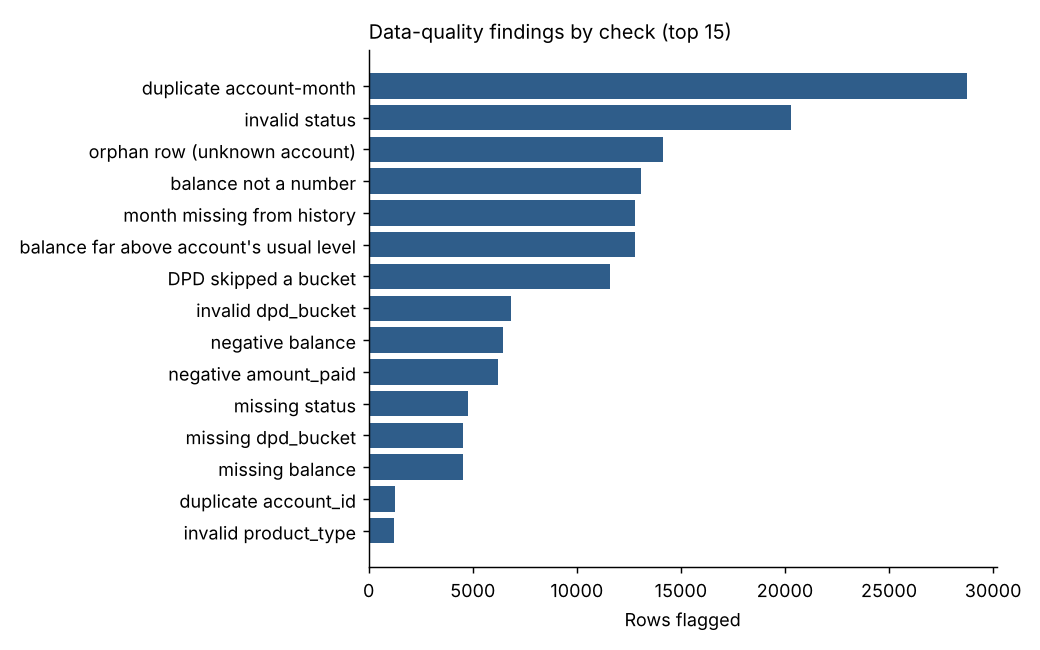

In [5]:
display(results["exceptions"])
display(Image("output/charts/1_findings.png"))

## 5. How good are the checks?

`creforge score` compares the findings with the answer key.

- **Recall:** share of injected faults the checks caught
- **Precision:** share of findings that were real faults (the rest are false alarms)

In [6]:
!creforge score dirty/faults.parquet output/findings.csv

# Data-quality score

- Faults injected: 155,554; findings submitted: 153,248
- **Recall: 98.3%** (injected faults your checks found)
- **Precision: 99.9%** (findings that were real faults)

| Fault type | Injected | Found | Recall |
|---|---|---|---|
| activity_after_closure | 272 | 272 | 100.0% |
| close_reason_mismatch | 263 | 262 | 99.6% |
| code_formatting | 14,191 | 13,951 | 98.3% |
| date_format | 832 | 595 | 71.5% |
| dpd_jump | 11,814 | 11,606 | 98.2% |
| duplicate_key | 14,925 | 14,925 | 100.0% |
| duplicate_row | 15,326 | 15,076 | 98.4% |
| future_date | 852 | 608 | 71.4% |
| missing_month | 12,791 | 12,791 | 100.0% |
| negative_amount | 12,678 | 12,678 | 100.0% |
| null_required | 14,950 | 14,703 | 98.3% |
| orphan_row | 14,848 | 14,151 | 95.3% |
| paid_while_rolling | 400 | 395 | 98.8% |
| scale_error | 13,127 | 12,934 | 98.5% |
| type_mismatch | 13,681 | 13,681 | 100.0% |
| unknown_code | 14,604 | 14,359 | 98.3% |



**Reading the score.** The pipeline only checks the three tables it uses (subject, account, account_month), and on those it catches about 99.7% of faults. Most of the misses are in the inquiry and account_party tables, which it never reads. The rest are mainly x100 errors on small balances: a small balance times 100 can still look normal, so a distribution check can't see it. That's a real limitation and worth saying out loud.

## 6. What cleaning removed

In [7]:
results["cleaned"]["cleaning_log"]

,step,table,rows removed
0,exact duplicate rows,account,638
1,duplicate account_id (kept first),account,632
2,missing required field,account,1214
3,invalid product_type,account,619
4,open_date in the future,account,608
5,credit_limit scale error,account,144
6,principal scale error,account,163
7,exact duplicate rows,account_month,14438
8,duplicate account-month (kept first),account_month,14293
9,orphan or excluded account,account_month,75327


## 7. Portfolio summary at the latest month

In [8]:
s = results["summary"]
display(s["portfolio_summary"])
display(s["writeoff_rates"])

,Accounts,Balance,% of balance,30+ DPD % (by balance),90+ DPD % (by balance),WA interest rate %
product,,,,,,
auto_loan,3389,170289938,6.50,1.49,0.75,4.51
bnpl,439,312485,0.00,2.60,0.75,0.00
credit_card,17607,86042446,3.30,3.58,1.61,17.67
mortgage,5568,2289969443,87.80,2.33,0.40,4.85
overdraft,1567,19534796,0.70,3.15,1.32,10.64
personal_loan,3839,42735431,1.60,1.77,0.45,10.26
Total,32409,2608884539,100.00,2.31,0.47,5.38


,Written off (12m),Average balance (12m),Annual write-off rate %
product,,,
auto_loan,"3,498,225.00","170,929,005.00",2.05
bnpl,790.00,"230,010.00",0.34
credit_card,"5,652,637.00","84,567,615.00",6.68
mortgage,"6,855,821.00","2,271,986,724.00",0.30
overdraft,"721,295.00","19,935,990.00",3.62
personal_loan,"1,266,772.00","45,101,511.00",2.81


## 8. Risk by grade

If the risk grades mean anything, the bad rate should rise steadily from A to E.

,accounts,Ever 90+ or written off %
risk_grade,,
A,12847,0.15
B,18413,1.11
C,16008,3.67
D,8819,16.19
E,4767,39.52


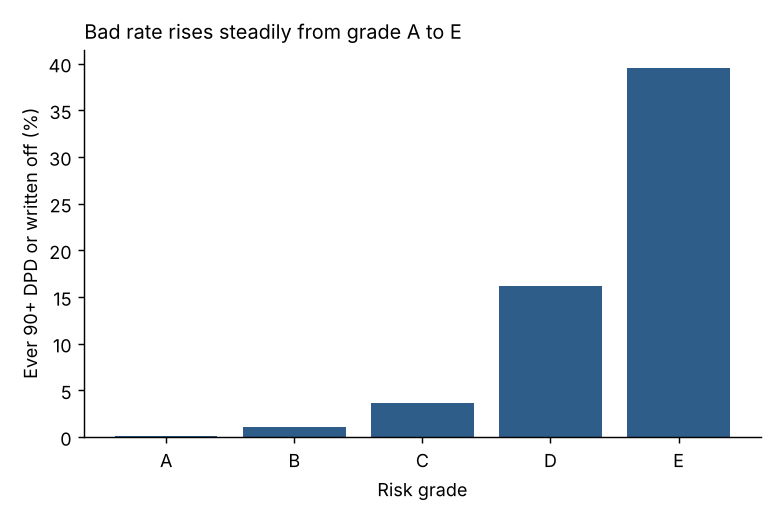

In [9]:
display(s["risk_by_grade"])
display(Image("output/charts/3_risk_by_grade.png"))

## 9. Arrears trend

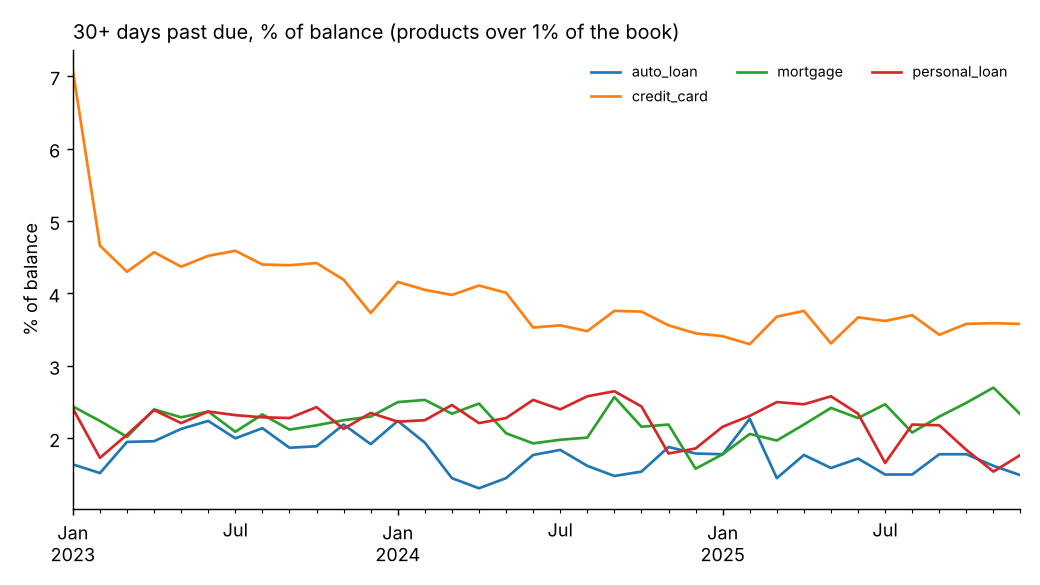

In [10]:
display(Image("output/charts/2_arrears_trend.png"))

## 10. Roll rates

Of the accounts in each arrears bucket this month, the share in each bucket next month. The diagonal is "stayed", right of it is "rolled worse", left is "cured or paid back". An account can only roll one bucket worse a month.

next_bucket,0,1-29,30-59,60-89,90-119,120+
dpd_bucket,,,,,,
0,98.36,1.64,0.00,0.00,0.00,0.00
1-29,51.74,13.05,35.20,0.00,0.00,0.00
30-59,25.87,11.64,14.04,48.45,0.00,0.00
60-89,23.90,0.20,7.13,14.83,53.94,0.00
90-119,11.85,0.00,0.00,5.31,14.34,68.50
120+,5.42,0.00,0.00,0.00,2.70,91.89


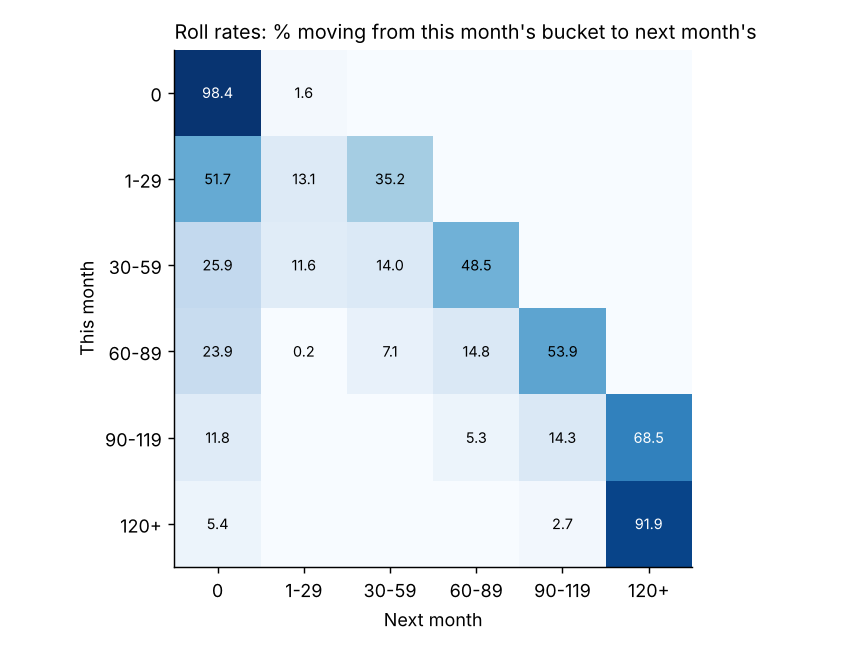

In [11]:
display(s["roll_rates"])
display(Image("output/charts/4_roll_rates.png"))

## 11. Vintage curves, auto loans

Cumulative % of accounts reaching 90+ days past due or written off, by months on book, one line per half-year of origination. Only loans opened inside the data window, so every vintage is seen from month 0. Each vintage has about 250 loans, so the lines are noisy.

vintage,2023-H1,2023-H2,2024-H1,2024-H2,2025-H1,2025-H2
accounts,327,259,242,259,243,241


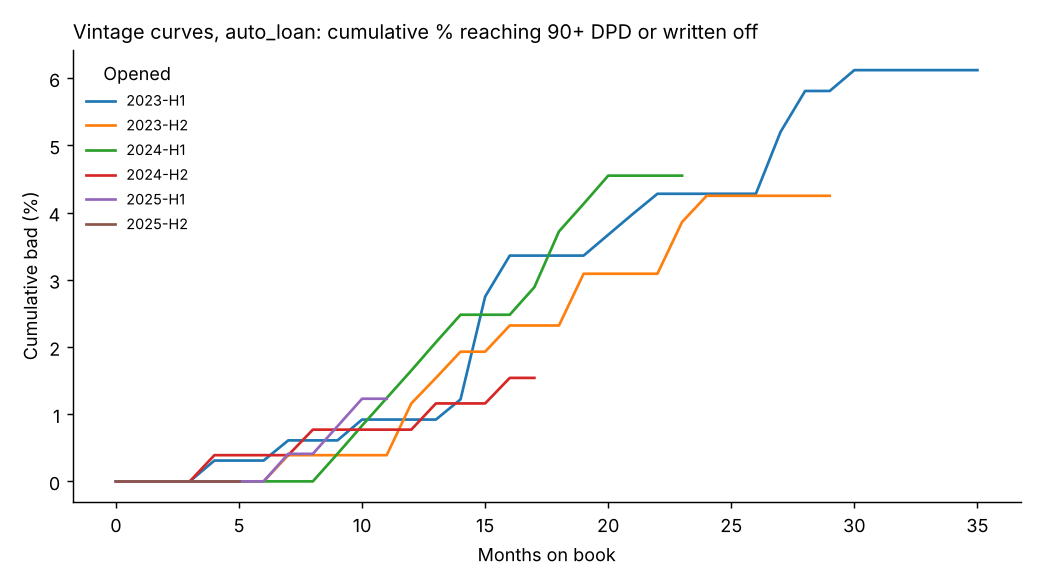

In [12]:
display(s["vintage_sizes"].T)
display(Image("output/charts/5_vintage_curves.png"))

## 12. Stress test: baseline vs stressed economy

Run the same pipeline on the stressed dataset. It's clean data, so this also tests the checks for false alarms.

**Result:** about 120 rows flagged out of 1.4 million, every one from the two outlier checks (a balance or limit far above normal). The rule-based checks raise no false alarms at all. Outlier checks always trade some false alarms for catching x100 errors; in practice those rows go to a person to review rather than being deleted automatically.

1. Load


  Loaded subject           20,000 rows
  Loaded account           63,811 rows
  Loaded account_month  1,419,642 rows
2. Validate


  122 findings across 122 rows
3. Clean


  Clean: 63,801 accounts, 1,419,349 account-months (303 rows removed)
4. Summarise


5. Report


  Saved output_stressed/report.xlsx, findings.csv and 5 charts


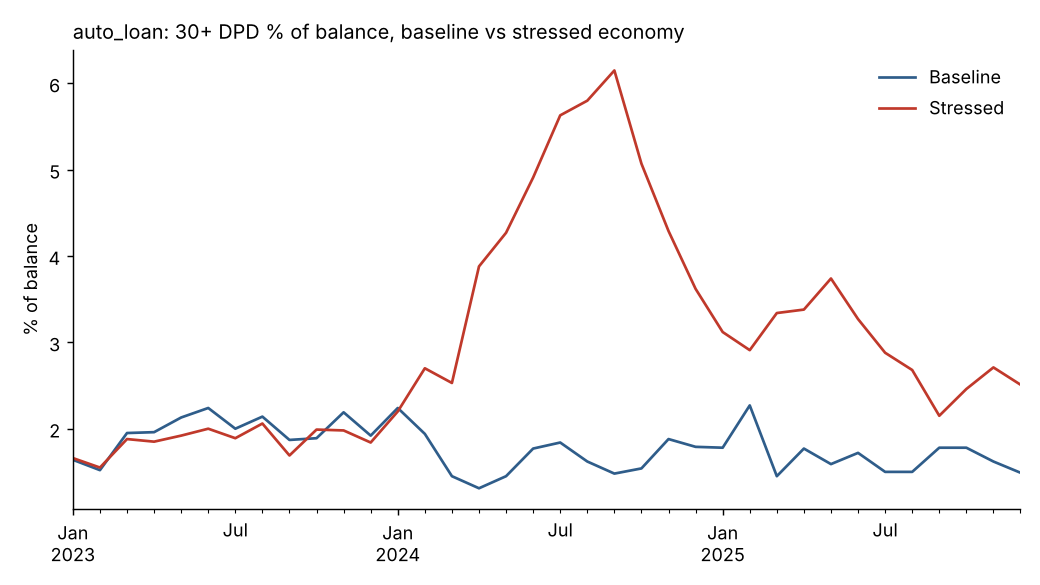

Peak auto 30+ DPD: {'Baseline': 2.27, 'Stressed': 6.15}


In [13]:
stressed = run("stressed", "output_stressed", product="auto_loan")
both, path = compare_scenarios(results["summary"], stressed["summary"], "auto_loan", "output")
display(Image(path))
print("Peak auto 30+ DPD:", both.max().round(2).to_dict())

## Files produced

- `output/report.xlsx`: every table, one sheet each
- `output/findings.csv`: every row flagged, for the servicer
- `output/charts/`: six charts